Đang sinh dữ liệu kênh truyền (h_k)...
Đang đếm số điểm Outage qua các mốc SNR...
Vẽ hình hoàn tất!


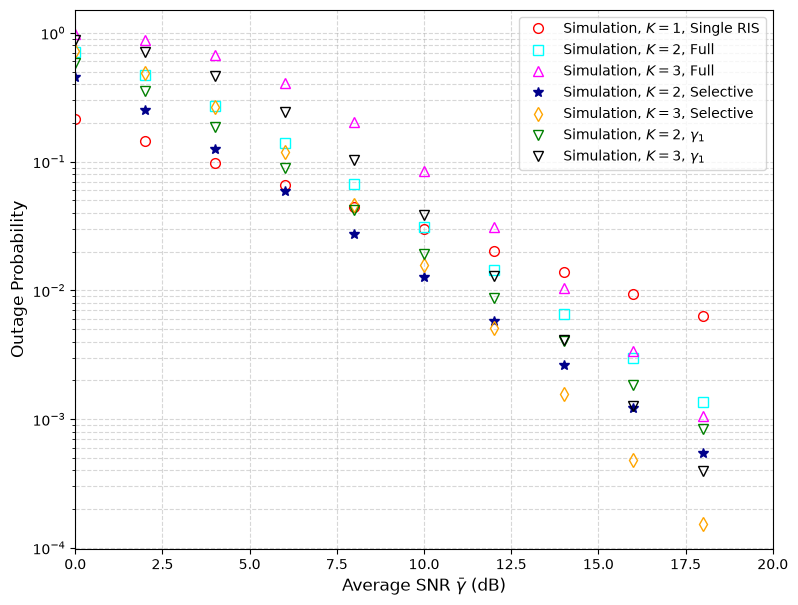

In [1]:

import numpy as np
import matplotlib.pyplot as plt
import sys
import os
# Nếu thư mục chứa 'src' nằm ở thư mục cha, dùng '..'
# Hoặc thay bằng đường dẫn tuyệt đối tới thư mục dự án của bạn
sys.path.append(os.path.abspath('..'))
from src.parameters import (
    SystemConfig, RISConfig, TurbulenceConfig, 
    PointingErrorConfig, ReceiverConfig
)
# Import các module đã viết
from src.parameters import SystemConfig, RISConfig, TurbulenceConfig, PointingErrorConfig, ReceiverConfig
from src.channel import generate_composite_fading
from src.outage import simulate_outage_curves

def plot_monte_carlo_outage():
    # 1. Cấu hình trục hoành: Average SNR quét từ 10 dB đến 40 dB giống Hình 2
    snr_db_array = np.arange(0,20, 2)
    snr_linear_array = 10.0 ** (snr_db_array / 10.0)
    
    # Số lượng mẫu Monte Carlo. Để 100_000 test cho nhanh. 
    # Muốn các điểm ở dải SNR > 30dB không bị chạm 0 (đứt gãy), hãy tăng lên 1_000_000.
    num_samples = 10000000

    # 2. Định nghĩa các cấu hình dùng chung (Dựa trên Hình 2 của bài báo)
    turb_config = TurbulenceConfig(alpha=3.35, beta=3.19)
    pe_config = PointingErrorConfig(sigma_theta=2.0e-3, sigma_phi=2.0e-3)
    rec_config = ReceiverConfig(gamma_th_db=13.0)

    # Khởi tạo 3 hệ thống cần so sánh (Tổng số phần tử luôn bằng 12)
    config_k1 = SystemConfig(ris=RISConfig(K=1, N=[12]), turbulence=turb_config, pointing_error=pe_config, receiver=rec_config)
    config_k2 = SystemConfig(ris=RISConfig(K=2, N=[6, 6]), turbulence=turb_config, pointing_error=pe_config, receiver=rec_config)
    config_k3 = SystemConfig(ris=RISConfig(K=3, N=[4, 4, 4]), turbulence=turb_config, pointing_error=pe_config, receiver=rec_config)

    config_k1.validate()
    config_k2.validate()
    config_k3.validate()

    # 3. Chạy mô phỏng kênh truyền (Sinh ma trận h_k)
    print("Đang sinh dữ liệu kênh truyền (h_k)...")
    h_k_matrix_k1 = generate_composite_fading(config_k1, num_samples)
    h_k_matrix_k2 = generate_composite_fading(config_k2, num_samples)
    h_k_matrix_k3 = generate_composite_fading(config_k3, num_samples)
    
    # 4. Tính toán Outage Probability
    print("Đang đếm số điểm Outage qua các mốc SNR...")
    p_full_k1, _, _= simulate_outage_curves(h_k_matrix_k1, snr_linear_array, config_k1.receiver.gamma_th)
    p_full_k2, p_sel_k2, p_1_k2 = simulate_outage_curves(h_k_matrix_k2, snr_linear_array, config_k2.receiver.gamma_th)
    p_full_k3, p_sel_k3, p_1_k3 = simulate_outage_curves(h_k_matrix_k3, snr_linear_array, config_k3.receiver.gamma_th)
   
    # Lọc bỏ các điểm có xác suất = 0.0 để đồ thị logarit không bị lỗi (Log(0) là vô cực)
    # Lỗi này xảy ra khi num_samples không đủ lớn để hứng được xác suất quá nhỏ
    def filter_zeros(arr):
        return np.where(arr == 0, np.nan, arr)

    # 5. Vẽ hình (Chỉ dùng marker, linestyle='None')
    plt.figure(figsize=(9, 7))
    
    # Cài đặt trục Y là trục Logarit
    plt.yscale('log')

    # Vẽ các điểm Monte Carlo (Màu và hình dạng giống hệt chú thích Hình 2)
    plt.plot(snr_db_array, filter_zeros(p_full_k1), marker='o', linestyle='None', color='red', markersize=7, fillstyle='none', label='Simulation, $K=1$, Single RIS')
   #plt.plot(snr_db_array, filter_zeros(p_1_k1), marker='*', linestyle='None', color='darkblue', markersize=7, label='Simulation, $K=1$, $\\gamma_1$')

    plt.plot(snr_db_array, filter_zeros(p_full_k2), marker='s', linestyle='None', color='cyan', markersize=7, fillstyle='none', label='Simulation, $K=2$, Full')
    plt.plot(snr_db_array, filter_zeros(p_full_k3), marker='^', linestyle='None', color='magenta', markersize=7, fillstyle='none', label='Simulation, $K=3$, Full')
    
    plt.plot(snr_db_array, filter_zeros(p_sel_k2), marker='*', linestyle='None', color='darkblue', markersize=7, label='Simulation, $K=2$, Selective')
    plt.plot(snr_db_array, filter_zeros(p_sel_k3), marker='d', linestyle='None', color='orange', markersize=7, fillstyle='none', label='Simulation, $K=3$, Selective')
   
    plt.plot(snr_db_array, filter_zeros(p_1_k2), marker='v', linestyle='None', color='green', markersize=7, fillstyle='none', label='Simulation, $K=2$, $\\gamma_1$')
    plt.plot(snr_db_array, filter_zeros(p_1_k3), marker='v', linestyle='None', color='black', markersize=7, fillstyle='none', label='Simulation, $K=3$, $\\gamma_1$')
    # Định dạng đồ thị
    plt.xlabel('Average SNR $\\bar{\\gamma}$ (dB)', fontsize=12)
    plt.ylabel('Outage Probability', fontsize=12)
    plt.xlim(0, 20)
    
    
    # Vẽ lưới
    plt.grid(True, which="both", linestyle='--', alpha=0.5)
    plt.legend(fontsize=10)
    
    print("Vẽ hình hoàn tất!")
    plt.show()

if __name__ == "__main__":
    plot_monte_carlo_outage()

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import sys
import os
# Nếu thư mục chứa 'src' nằm ở thư mục cha, dùng '..'
# Hoặc thay bằng đường dẫn tuyệt đối tới thư mục dự án của bạn
sys.path.append(os.path.abspath('..'))
from src.parameters import (
    SystemConfig, RISConfig, TurbulenceConfig, 
    PointingErrorConfig, ReceiverConfig
)
# Import các module đã viết
from src.parameters import SystemConfig, RISConfig, TurbulenceConfig, PointingErrorConfig, ReceiverConfig
from src.channel import generate_composite_fading
from src.outage import simulate_outage_curves

def plot_figure_3():
    # 1. Cấu hình trục hoành: Average SNR quét từ 0 dB đến 35 dB (theo Hình 3)
    snr_db_array = np.arange(0, 36, 2)
    snr_linear_array = 10.0 ** (snr_db_array / 10.0)
    
    # Giữ nguyên 100,000 mẫu. Nếu muốn hiển thị rõ các điểm ở dải SNR > 25dB,
    # bạn có thể nâng num_samples lên 1_000_000.
    num_samples = 1000000 

    # 2. Định nghĩa các cấu hình dùng chung (Theo thông số caption Hình 3)
    turb_config = TurbulenceConfig(alpha=3.35, beta=3.19)
    pe_config = PointingErrorConfig(sigma_theta=2.0e-3, sigma_phi=2.0e-3)
    rec_config = ReceiverConfig(gamma_th_db=13.0)

    # Khởi tạo 3 hệ thống cần so sánh (K=2 cố định, thay đổi N_k)
    config_n6  = SystemConfig(ris=RISConfig(K=2, N=[6, 6]), turbulence=turb_config, pointing_error=pe_config, receiver=rec_config)
    config_n10 = SystemConfig(ris=RISConfig(K=2, N=[10, 10]), turbulence=turb_config, pointing_error=pe_config, receiver=rec_config)
    config_n14 = SystemConfig(ris=RISConfig(K=2, N=[14, 14]), turbulence=turb_config, pointing_error=pe_config, receiver=rec_config)

    config_n6.validate()
    config_n10.validate()
    config_n14.validate()

    # 3. Chạy mô phỏng kênh truyền (Sinh ma trận h_k)
    print("Đang sinh dữ liệu kênh truyền (h_k)...")
    h_k_n6  = generate_composite_fading(config_n6, num_samples)
    h_k_n10 = generate_composite_fading(config_n10, num_samples)
    h_k_n14 = generate_composite_fading(config_n14, num_samples)

    # 4. Tính toán Outage Probability
    print("Đang đếm số điểm Outage qua các mốc SNR...")
    p_full_n6, p_sel_n6   = simulate_outage_curves(h_k_n6, snr_linear_array, config_n6.receiver.gamma_th)
    p_full_n10, p_sel_n10 = simulate_outage_curves(h_k_n10, snr_linear_array, config_n10.receiver.gamma_th)
    p_full_n14, p_sel_n14 = simulate_outage_curves(h_k_n14, snr_linear_array, config_n14.receiver.gamma_th)

    # Hàm lọc số 0 để tránh lỗi toán học khi vẽ log(0)
    def filter_zeros(arr):
        return np.where(arr == 0, np.nan, arr)

    # 5. Vẽ hình (Chỉ vẽ marker mô phỏng Monte Carlo)
    plt.figure(figsize=(9, 7))
    plt.yscale('log')

    # Nhóm 1: Full Receiving Scheme
    plt.plot(snr_db_array, filter_zeros(p_full_n6), marker='o', linestyle='None', color='red', markersize=7, fillstyle='none', label='Simulation, $N_k=6$, Full')
    plt.plot(snr_db_array, filter_zeros(p_full_n10), marker='s', linestyle='None', color='cyan', markersize=7, fillstyle='none', label='Simulation, $N_k=10$, Full')
    plt.plot(snr_db_array, filter_zeros(p_full_n14), marker='^', linestyle='None', color='magenta', markersize=7, fillstyle='none', label='Simulation, $N_k=14$, Full')

    # Nhóm 2: Selective Receiving Scheme
    plt.plot(snr_db_array, filter_zeros(p_sel_n6), marker='*', linestyle='None', color='darkblue', markersize=7, label='Simulation, $N_k=6$, Selective')
    plt.plot(snr_db_array, filter_zeros(p_sel_n10), marker='d', linestyle='None', color='orange', markersize=7, fillstyle='none', label='Simulation, $N_k=10$, Selective')
    plt.plot(snr_db_array, filter_zeros(p_sel_n14), marker='p', linestyle='None', color='dimgray', markersize=7, fillstyle='none', label='Simulation, $N_k=14$, Selective')

    # Định dạng đồ thị giống bài báo
    plt.xlabel('Average SNR $\\bar{\\gamma}$ (dB)', fontsize=12)
    plt.ylabel('Outage Probability', fontsize=12)
    plt.xlim(10, 40)
    plt.ylim(1e-5, 1)
   
    # Cấu hình lưới và chú thích
    plt.grid(True, which="both", linestyle='--', alpha=0.5)
    plt.legend(fontsize=10)
    
    print("Vẽ hình hoàn tất!")
    plt.show()

if __name__ == "__main__":
    plot_figure_3()

Đang sinh dữ liệu kênh truyền (h_k)...
Đang đếm số điểm Outage qua các mốc SNR...


ValueError: too many values to unpack (expected 2)

Đang sinh dữ liệu kênh truyền (h_k)...
Đang đếm số điểm Outage qua các mốc SNR...
Vẽ hình hoàn tất!


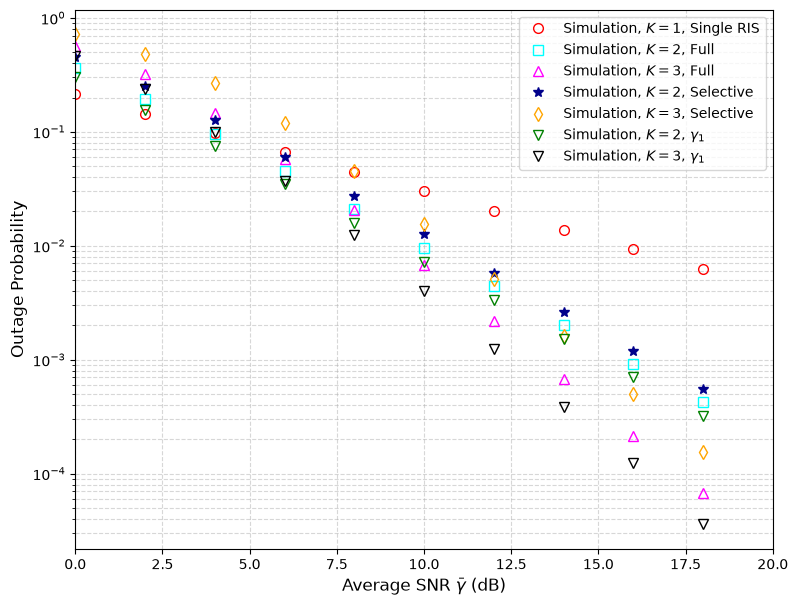

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import sys
import os
# Nếu thư mục chứa 'src' nằm ở thư mục cha, dùng '..'
# Hoặc thay bằng đường dẫn tuyệt đối tới thư mục dự án của bạn
sys.path.append(os.path.abspath('..'))
from src.parameters import (
    SystemConfig, RISConfig, TurbulenceConfig, 
    PointingErrorConfig, ReceiverConfig
)
# Import các module đã viết
from src.parameters import SystemConfig, RISConfig, TurbulenceConfig, PointingErrorConfig, ReceiverConfig
from src.channel import generate_composite_fading
from src.outage import simulate_outage_curves, simulate_outage_curves2

def plot_monte_carlo_outage():
    # 1. Cấu hình trục hoành: Average SNR quét từ 10 dB đến 40 dB giống Hình 2
    snr_db_array = np.arange(0,20, 2)
    snr_linear_array = 10.0 ** (snr_db_array / 10.0)
    
    # Số lượng mẫu Monte Carlo. Để 100_000 test cho nhanh. 
    # Muốn các điểm ở dải SNR > 30dB không bị chạm 0 (đứt gãy), hãy tăng lên 1_000_000.
    num_samples = 10000000

    # 2. Định nghĩa các cấu hình dùng chung (Dựa trên Hình 2 của bài báo)
    turb_config = TurbulenceConfig(alpha=3.35, beta=3.19)
    pe_config = PointingErrorConfig(sigma_theta=2.0e-3, sigma_phi=2.0e-3)
    rec_config = ReceiverConfig(gamma_th_db=13.0)

    # Khởi tạo 3 hệ thống cần so sánh (Tổng số phần tử luôn bằng 12)
    config_k1 = SystemConfig(ris=RISConfig(K=1, N=[12]), turbulence=turb_config, pointing_error=pe_config, receiver=rec_config)
    config_k2 = SystemConfig(ris=RISConfig(K=2, N=[6, 6]), turbulence=turb_config, pointing_error=pe_config, receiver=rec_config)
    config_k3 = SystemConfig(ris=RISConfig(K=3, N=[4, 4, 4]), turbulence=turb_config, pointing_error=pe_config, receiver=rec_config)

    config_k1.validate()
    config_k2.validate()
    config_k3.validate()

    # 3. Chạy mô phỏng kênh truyền (Sinh ma trận h_k)
    print("Đang sinh dữ liệu kênh truyền (h_k)...")
    h_k_matrix_k1 = generate_composite_fading(config_k1, num_samples)
    h_k_matrix_k2 = generate_composite_fading(config_k2, num_samples)
    h_k_matrix_k3 = generate_composite_fading(config_k3, num_samples)
    
    # 4. Tính toán Outage Probability
    print("Đang đếm số điểm Outage qua các mốc SNR...")
    p_full_k1, _, _= simulate_outage_curves2(h_k_matrix_k1, snr_linear_array, config_k1.receiver.gamma_th)
    p_full_k2, p_sel_k2, p_1_k2 = simulate_outage_curves2(h_k_matrix_k2, snr_linear_array, config_k2.receiver.gamma_th)
    p_full_k3, p_sel_k3, p_1_k3 = simulate_outage_curves2(h_k_matrix_k3, snr_linear_array, config_k3.receiver.gamma_th)
   
    # Lọc bỏ các điểm có xác suất = 0.0 để đồ thị logarit không bị lỗi (Log(0) là vô cực)
    # Lỗi này xảy ra khi num_samples không đủ lớn để hứng được xác suất quá nhỏ
    def filter_zeros(arr):
        return np.where(arr == 0, np.nan, arr)

    # 5. Vẽ hình (Chỉ dùng marker, linestyle='None')
    plt.figure(figsize=(9, 7))
    
    # Cài đặt trục Y là trục Logarit
    plt.yscale('log')

    # Vẽ các điểm Monte Carlo (Màu và hình dạng giống hệt chú thích Hình 2)
    plt.plot(snr_db_array, filter_zeros(p_full_k1), marker='o', linestyle='None', color='red', markersize=7, fillstyle='none', label='Simulation, $K=1$, Single RIS')
   #plt.plot(snr_db_array, filter_zeros(p_1_k1), marker='*', linestyle='None', color='darkblue', markersize=7, label='Simulation, $K=1$, $\\gamma_1$')

    plt.plot(snr_db_array, filter_zeros(p_full_k2), marker='s', linestyle='None', color='cyan', markersize=7, fillstyle='none', label='Simulation, $K=2$, Full')
    plt.plot(snr_db_array, filter_zeros(p_full_k3), marker='^', linestyle='None', color='magenta', markersize=7, fillstyle='none', label='Simulation, $K=3$, Full')
    
    plt.plot(snr_db_array, filter_zeros(p_sel_k2), marker='*', linestyle='None', color='darkblue', markersize=7, label='Simulation, $K=2$, Selective')
    plt.plot(snr_db_array, filter_zeros(p_sel_k3), marker='d', linestyle='None', color='orange', markersize=7, fillstyle='none', label='Simulation, $K=3$, Selective')
   
    plt.plot(snr_db_array, filter_zeros(p_1_k2), marker='v', linestyle='None', color='green', markersize=7, fillstyle='none', label='Simulation, $K=2$, $\\gamma_1$')
    plt.plot(snr_db_array, filter_zeros(p_1_k3), marker='v', linestyle='None', color='black', markersize=7, fillstyle='none', label='Simulation, $K=3$, $\\gamma_1$')
    # Định dạng đồ thị
    plt.xlabel('Average SNR $\\bar{\\gamma}$ (dB)', fontsize=12)
    plt.ylabel('Outage Probability', fontsize=12)
    plt.xlim(0, 20)
    
    
    # Vẽ lưới
    plt.grid(True, which="both", linestyle='--', alpha=0.5)
    plt.legend(fontsize=10)
    
    print("Vẽ hình hoàn tất!")
    plt.show()

if __name__ == "__main__":
    plot_monte_carlo_outage()

Khởi tạo truyền 20000000 bits qua không gian nước...
Đang chạy luồng bắn dữ liệu cho K=1...
Đang chạy luồng bắn dữ liệu cho K=2...
Đang chạy luồng bắn dữ liệu cho K=3...
Vẽ hình hoàn tất!


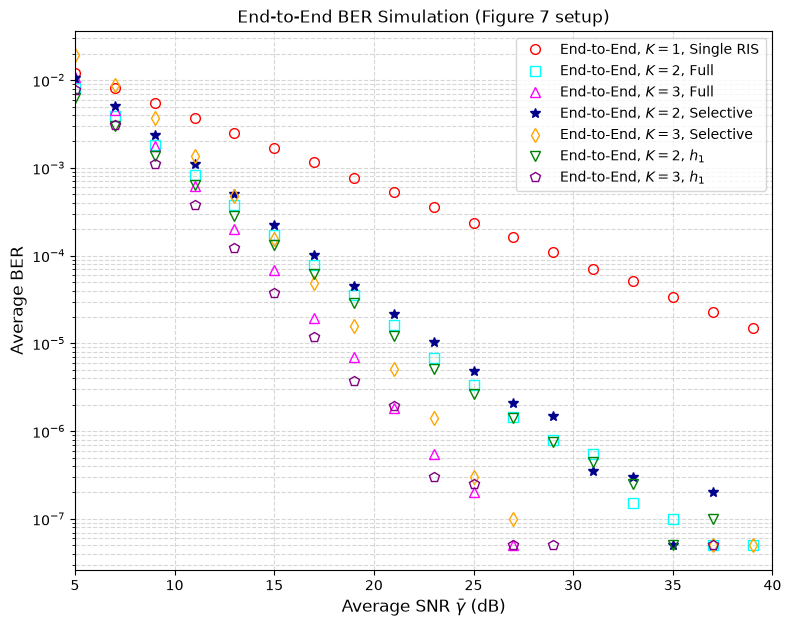

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import sys
import os

# Nếu thư mục chứa 'src' nằm ở thư mục cha, dùng '..'
# Hoặc thay bằng đường dẫn tuyệt đối tới thư mục dự án của bạn
sys.path.append(os.path.abspath('..'))

from src.parameters import SystemConfig, RISConfig, TurbulenceConfig, PointingErrorConfig, ReceiverConfig
from src.channel import generate_composite_fading
from src.ber_full import simulate_end_to_end_ber
R_s=1
def plot_end_to_end_ber():
    snr_db_array = np.arange(5, 40, 2)   
    # Yêu cầu 10^6 bits => Tương đương 500,000 symbols (điểm dữ liệu kênh truyền)
    num_symbols = 10000000    
    print(f"Khởi tạo truyền {num_symbols * 2} bits qua không gian nước...")
    # Cấu hình dùng chung
    turb_config = TurbulenceConfig(alpha=3.35, beta=3.19)
    pe_config = PointingErrorConfig(sigma_theta=2.0e-3, sigma_phi=2.0e-3)
    rec_config = ReceiverConfig(gamma_th_db=13.0)

    # -------------------------------------------------------------
    # BƯỚC 1: CẤU HÌNH RIS CHO K=1, 2, 3 (TỔNG N = 12)
    # -------------------------------------------------------------
    config_k1 = SystemConfig(ris=RISConfig(K=1, N=[12]), turbulence=turb_config, pointing_error=pe_config, receiver=rec_config)
    config_k2 = SystemConfig(ris=RISConfig(K=2, N=[6, 6]), turbulence=turb_config, pointing_error=pe_config, receiver=rec_config)
    config_k3 = SystemConfig(ris=RISConfig(K=3, N=[4, 4, 4]), turbulence=turb_config, pointing_error=pe_config, receiver=rec_config)
   
    # Sinh kênh truyền h_k gốc cho từng cấu hình
    h_k_matrix_k1 = generate_composite_fading(config_k1, num_samples=num_symbols)
    h_k_matrix_k2 = generate_composite_fading(config_k2, num_samples=num_symbols)
    h_k_matrix_k3 = generate_composite_fading(config_k3, num_samples=num_symbols)
    
    # -------------------------------------------------------------
    # BƯỚC 2: TRÍCH XUẤT KÊNH TRUYỀN HIỆU DỤNG (h_eff)
    # -------------------------------------------------------------
    # Đối với K = 1
    h_eff_k1 = np.sum(h_k_matrix_k1, axis=1) / config_k1.ris.K
    
    # Đối với K = 2
    h_eff_full_k2 = np.sum(h_k_matrix_k2, axis=1) /np.sqrt(config_k2.ris.K)
    h_eff_sel_k2 = np.max(h_k_matrix_k2, axis=1)
    h_1_k2=np.sqrt(np.sum(h_k_matrix_k2**2,axis=1))  # Tính h_1 cho K=2
    # Đối với K = 3
    h_eff_full_k3 = np.sum(h_k_matrix_k3, axis=1) /np.sqrt(config_k3.ris.K)
    h_eff_sel_k3 = np.max(h_k_matrix_k3, axis=1)
    h_1_k3=np.sqrt(np.sum(h_k_matrix_k3**2,axis=1))  # Tính h_1 cho K=3
    
    # -------------------------------------------------------------
    # BƯỚC 3: CHẠY MÔ PHỎNG END-TO-END
    # -------------------------------------------------------------
    print("Đang chạy luồng bắn dữ liệu cho K=1...")
    ber_k1 = simulate_end_to_end_ber(h_eff_k1, snr_db_array)

    print("Đang chạy luồng bắn dữ liệu cho K=2...")
    ber_full_k2 = simulate_end_to_end_ber(h_eff_full_k2, snr_db_array)
    ber_sel_k2 = simulate_end_to_end_ber(h_eff_sel_k2, snr_db_array)
    ber_1_k2 = simulate_end_to_end_ber(h_1_k2, snr_db_array)

    print("Đang chạy luồng bắn dữ liệu cho K=3...")
    ber_full_k3 = simulate_end_to_end_ber(h_eff_full_k3, snr_db_array)
    ber_sel_k3 = simulate_end_to_end_ber(h_eff_sel_k3, snr_db_array)
    ber_1_k3 = simulate_end_to_end_ber(h_1_k3, snr_db_array)
    # Lọc giá trị 0 để biểu đồ logarit không bị lỗi
    def filter_zeros(arr):
        return np.where(arr == 0, np.nan, arr)
    # -------------------------------------------------------------
   # Bước 4: 
    # -------------------------------------------------------------
    plt.figure(figsize=(9, 7))
    plt.yscale('log')
   
    # Vẽ các đường (chỉ dùng marker, không kẻ line)
    plt.plot(snr_db_array, filter_zeros(ber_k1), marker='o', linestyle='None', color='red', fillstyle='none', markersize=7, label='End-to-End, $K=1$, Single RIS')
    
    plt.plot(snr_db_array, filter_zeros(ber_full_k2), marker='s', linestyle='None', color='cyan', fillstyle='none', markersize=7, label='End-to-End, $K=2$, Full')
    plt.plot(snr_db_array, filter_zeros(ber_full_k3), marker='^', linestyle='None', color='magenta', fillstyle='none', markersize=7, label='End-to-End, $K=3$, Full')
    
    plt.plot(snr_db_array, filter_zeros(ber_sel_k2), marker='*', linestyle='None', color='darkblue', markersize=7, label='End-to-End, $K=2$, Selective')
    plt.plot(snr_db_array, filter_zeros(ber_sel_k3), marker='d', linestyle='None', color='orange', fillstyle='none', markersize=7, label='End-to-End, $K=3$, Selective')
   
    plt.plot(snr_db_array, filter_zeros(ber_1_k2), marker='v', linestyle='None', color='green', fillstyle='none', markersize=7, label='End-to-End, $K=2$, $h_1$')
    plt.plot(snr_db_array, filter_zeros(ber_1_k3), marker='p', linestyle='None', color='purple', fillstyle='none', markersize=7, label='End-to-End, $K=3$, $h_1$')
    #---------------------------------------------------------------------------------------------------------------------------------------------------------------------
    # plt.plot(snr_db_array, filter_zeros(ber_full_k2), marker='v', linestyle='None', color='cyan', fillstyle='none', markersize=7, label='End-to-End, $K=2$, Full')
    # plt.plot(snr_db_array, filter_zeros(ber_full_k3), marker='$', linestyle='None', color='magenta', fillstyle='none', markersize=7, label='End-to-End, $K=3$, Full')
    # Định dạng đồ thị giống Hình 7
    plt.xlabel('Average SNR $\\bar{\\gamma}$ (dB)', fontsize=12)
    plt.ylabel('Average BER', fontsize=12)
    plt.xlim(5, 40)
    # plt.ylim(1e-7, 1e-1)   
    plt.grid(True, which="both", linestyle='--', alpha=0.5)
    plt.legend(fontsize=10)
    plt.title("End-to-End BER Simulation (Figure 7 setup)")
  
    print("Vẽ hình hoàn tất!")
    plt.show()  
if __name__ == "__main__":
    plot_end_to_end_ber()

In [2]:
# ============================================================
# SO SÁNH THROUGHPUT CỦA 4 CƠ CHẾ
#
# 1. Full Receiving + AMC
# 2. Selective Receiving + AMC
# 3. Full Receiving cố định 4-PAM
# 4. Selective Receiving cố định 4-PAM
#
# K = 2
# QoS = 10^-4
# Số mẫu channel = 1.000.000
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys
import os

# Nếu thư mục chứa 'src' nằm ở thư mục cha, dùng '..'
# Hoặc thay bằng đường dẫn tuyệt đối tới thư mục dự án của bạn
sys.path.append(os.path.abspath('..'))

from src.channel import generate_composite_fading
from src.snr import calculate_gamma_f, calculate_gamma_s
from src.parameters import SystemConfig, RISConfig, TurbulenceConfig, PointingErrorConfig, ReceiverConfig

# ============================================================
# 1. CẤU HÌNH
# ============================================================

NUM_CHANNEL_SAMPLES = 1_000_000
TARGET_BER = 1e-4

# Các mốc SNR trung bình cần tính throughput
snr_bar_db_array = np.arange(0.0, 31.0, 2.0)
turb_config = TurbulenceConfig(alpha=3.35, beta=3.19)
pe_config = PointingErrorConfig(sigma_theta=2.0e-3, sigma_phi=2.0e-3)
rec_config = ReceiverConfig(gamma_th_db=13.0)

    # -------------------------------------------------------------
    # BƯỚC 1: CẤU HÌNH RIS CHO K=1, 2, 3 (TỔNG N = 12)
    # -------------------------------------------------------------
config_k1 = SystemConfig(ris=RISConfig(K=1, N=[12]), turbulence=turb_config, pointing_error=pe_config, receiver=rec_config)
config_k2 = SystemConfig(ris=RISConfig(K=2, N=[6, 6]), turbulence=turb_config, pointing_error=pe_config, receiver=rec_config)
# Dùng cấu hình K=2 đã tạo ở các cell trước
throughput_config = config_k2

if throughput_config.ris.K != 2:
    raise ValueError(
        f"Cấu hình hiện tại có K={throughput_config.ris.K}, "
        "nhưng yêu cầu K=2."
    )


# ============================================================
# 2. NGƯỠNG AMC CHO QoS = 10^-4
# ============================================================

# Các ngưỡng lấy từ ảnh:
#
# 2-PAM  : 11.4 dB
# 4-PAM  : 19.7 dB
# 8-PAM  : 26.5 dB
# 16-PAM : 32.8 dB

snr_thresholds_db = np.array(
    [11.4, 19.7, 26.5, 32.8],
    dtype=float,
)

modulation_orders = np.array(
    [2, 4, 8, 16],
    dtype=int,
)

bits_per_symbol = np.log2(modulation_orders)

# Ngưỡng để truyền cố định 4-PAM
pam4_threshold_db = snr_thresholds_db[1]
pam4_rate = 2.0


# ============================================================
# 3. SINH CHANNEL GAIN
# ============================================================

print(
    f"Đang sinh {NUM_CHANNEL_SAMPLES:,} mẫu channel "
    "cho hệ thống K=2..."
)

h_k_matrix_k2_amc = generate_composite_fading(
    config=throughput_config,
    num_samples=NUM_CHANNEL_SAMPLES,
)

if h_k_matrix_k2_amc.shape != (
    NUM_CHANNEL_SAMPLES,
    2,
):
    raise RuntimeError(
        "Kích thước h_k_matrix không đúng: "
        f"{h_k_matrix_k2_amc.shape}"
    )

if not np.all(np.isfinite(h_k_matrix_k2_amc)):
    raise RuntimeError(
        "h_k_matrix chứa NaN hoặc Inf."
    )

if np.any(h_k_matrix_k2_amc < 0):
    raise RuntimeError(
        "Channel gain phải không âm."
    )


# ============================================================
# 4. HÀM TÍNH THROUGHPUT AMC
# ============================================================

def calculate_amc_throughput(
    snr_inst_db,
    snr_thresholds_db,
    modulation_orders,
):
    """
    Tính throughput trung bình của AMC.

    Quy tắc:
        SNR < 11.4 dB       -> 0 bit/symbol
        11.4 - 19.7 dB      -> 2-PAM  = 1 bit/symbol
        19.7 - 26.5 dB      -> 4-PAM  = 2 bit/symbol
        26.5 - 32.8 dB      -> 8-PAM  = 3 bit/symbol
        SNR >= 32.8 dB      -> 16-PAM = 4 bit/symbol
    """
    snr_inst_db = np.asarray(snr_inst_db, dtype=float)

    if not np.all(np.isfinite(snr_inst_db)):
        raise ValueError(
            "SNR tức thời chứa NaN hoặc Inf."
        )

    # region_index:
    # 0 -> chưa đạt ngưỡng 2-PAM
    # 1 -> chọn 2-PAM
    # 2 -> chọn 4-PAM
    # 3 -> chọn 8-PAM
    # 4 -> chọn 16-PAM
    region_index = np.searchsorted(
        snr_thresholds_db,
        snr_inst_db,
        side="right",
    )

    rate_per_sample = np.zeros(
        snr_inst_db.shape,
        dtype=float,
    )

    active = region_index > 0
    selected_index = region_index[active] - 1

    rate_per_sample[active] = np.log2(
        modulation_orders[selected_index]
    )

    return np.mean(rate_per_sample)




throughput_results = []
def calculate_amc_rate_per_sample(
    snr_inst_db,
    snr_thresholds_db,
    modulation_orders,
):
    """
    Chọn rate riêng cho từng channel realization.

    SNR dưới ngưỡng 2-PAM có rate bằng 0.
    """
    snr_inst_db = np.asarray(
        snr_inst_db,
        dtype=float,
    )

    region_index = np.searchsorted(
        snr_thresholds_db,
        snr_inst_db,
        side="right",
    )

    rate_per_sample = np.zeros(
        snr_inst_db.shape,
        dtype=float,
    )

    active = region_index > 0
    selected_index = region_index[active] - 1

    rate_per_sample[active] = np.log2(
        modulation_orders[selected_index]
    )

    return rate_per_sample
print("Đang tính throughput...")

# ============================================================
# 5. TÍNH THROUGHPUT CHO 4 CƠ CHẾ
# ============================================================

throughput_results = []

print("Đang tính throughput...")

for snr_bar_db in snr_bar_db_array:

    # SNR trung bình dạng tuyến tính
    snr_bar_linear = 10.0 ** (
        snr_bar_db / 10.0
    )

    # ========================================================
    # TWO-STREAM RECEIVING + AMC
    #
    # Stream 1 dùng h1
    # Stream 2 dùng h2
    # Mỗi stream nhận 1/2 tổng công suất
    # ========================================================

    h_stream_1 = h_k_matrix_k2_amc[:, 0]
    h_stream_2 = h_k_matrix_k2_amc[:, 1]

    gamma_stream_1_linear = (
        snr_bar_linear * h_stream_1 ** 2 / 2.0
    )

    gamma_stream_2_linear = (
        snr_bar_linear * h_stream_2 ** 2 / 2.0
    )

    gamma_stream_1_db = 10.0 * np.log10(
        np.maximum(
            gamma_stream_1_linear,
            np.finfo(float).tiny,
        )
    )

    gamma_stream_2_db = 10.0 * np.log10(
        np.maximum(
            gamma_stream_2_linear,
            np.finfo(float).tiny,
        )
    )

    rate_stream_1 = calculate_amc_rate_per_sample(
        snr_inst_db=gamma_stream_1_db,
        snr_thresholds_db=snr_thresholds_db,
        modulation_orders=modulation_orders,
    )

    rate_stream_2 = calculate_amc_rate_per_sample(
        snr_inst_db=gamma_stream_2_db,
        snr_thresholds_db=snr_thresholds_db,
        modulation_orders=modulation_orders,
    )

    # Hai stream truyền song song nên cộng throughput
    throughput_two_stream_amc = np.mean(
        rate_stream_1 + rate_stream_2
    )

    # ========================================================
    # SELECTIVE RECEIVING + AMC
    # ========================================================

    gamma_selective_linear = calculate_gamma_s(
        gamma_bar=snr_bar_linear,
        h_k_matrix=h_k_matrix_k2_amc,
    )

    gamma_selective_db = 10.0 * np.log10(
        np.maximum(
            gamma_selective_linear,
            np.finfo(float).tiny,
        )
    )

    throughput_selective_amc = np.mean(
        calculate_amc_rate_per_sample(
            snr_inst_db=gamma_selective_db,
            snr_thresholds_db=snr_thresholds_db,
            modulation_orders=modulation_orders,
        )
    )

    # ========================================================
    # FULL RECEIVING CỐ ĐỊNH 4-PAM
    # ========================================================

    gamma_full_linear = calculate_gamma_f(
        gamma_bar=snr_bar_linear,
        h_k_matrix=h_k_matrix_k2_amc,
    )

    gamma_full_db = 10.0 * np.log10(
        np.maximum(
            gamma_full_linear,
            np.finfo(float).tiny,
        )
    )

    throughput_full_4pam = pam4_rate * np.mean(
        gamma_full_db >= pam4_threshold_db
    )

    # ========================================================
    # SELECTIVE RECEIVING CỐ ĐỊNH 4-PAM
    # ========================================================

    throughput_selective_4pam = pam4_rate * np.mean(
        gamma_selective_db >= pam4_threshold_db
    )

    # Lưu kết quả của đúng mốc SNR hiện tại
    throughput_results.append({
        "SNR_trung_binh_dB": snr_bar_db,
        "Two_Stream_AMC": throughput_two_stream_amc,
        "Selective_AMC": throughput_selective_amc,
        "Full_4PAM": throughput_full_4pam,
        "Selective_4PAM": throughput_selective_4pam,
    })


throughput_results = pd.DataFrame(
    throughput_results
)

display(throughput_results.round(6))


# ============================================================
# 6. VẼ BIỂU ĐỒ SO SÁNH THROUGHPUT
# ============================================================

# ============================================================
# VẼ CÁC ĐIỂM MÔ PHỎNG THROUGHPUT
# Không nối line giữa các điểm
# ============================================================

plt.figure(figsize=(10, 7))

plt.plot(
    throughput_results["SNR_trung_binh_dB"],
    throughput_results["Two_Stream_AMC"],
    marker="o",
    linestyle="None",
    color="red",
    fillstyle="none",
    markersize=8,
    label="Two-Stream Receiving + AMC",
)

plt.plot(
    throughput_results["SNR_trung_binh_dB"],
    throughput_results["Selective_AMC"],
    marker="d",
    linestyle="None",
    color="blue",
    fillstyle="none",
    markersize=8,
    label="Selective Receiving + AMC",
)

plt.plot(
    throughput_results["SNR_trung_binh_dB"],
    throughput_results["Full_4PAM"],
    marker="s",
    linestyle="None",
    color="green",
    fillstyle="none",
    markersize=8,
    label="Full Receiving, 4-PAM",
)

plt.plot(
    throughput_results["SNR_trung_binh_dB"],
    throughput_results["Selective_4PAM"],
    marker="^",
    linestyle="None",
    color="orange",
    fillstyle="none",
    markersize=8,
    label="Selective Receiving, 4-PAM",
)

plt.xlabel(
    "Average SNR (dB)",
    fontsize=12,
)

plt.ylabel(
    "Average Throughput (bit/s)",
    fontsize=12,
)

plt.title(
    r"Throughput comparison, $K=2$, QoS=$10^{-4}$",
    fontsize=13,
)

# Các điểm SNR cách nhau 5 dB
plt.xticks(snr_bar_db_array)

plt.grid(
    True,
    which="both",
    linestyle="--",
    alpha=0.5,
)

plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

Đang sinh 1,000,000 mẫu channel cho hệ thống K=2...
Đang tính throughput...
Đang tính throughput...


KeyboardInterrupt: 

Analytical AMC thresholds (dB) at PER target: {2: 8.341538295894036, 4: 16.453905735775, 8: 23.126907530394604, 16: 29.295971254993308}
Simulation completed in 230.6 s
SNR points: [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30]


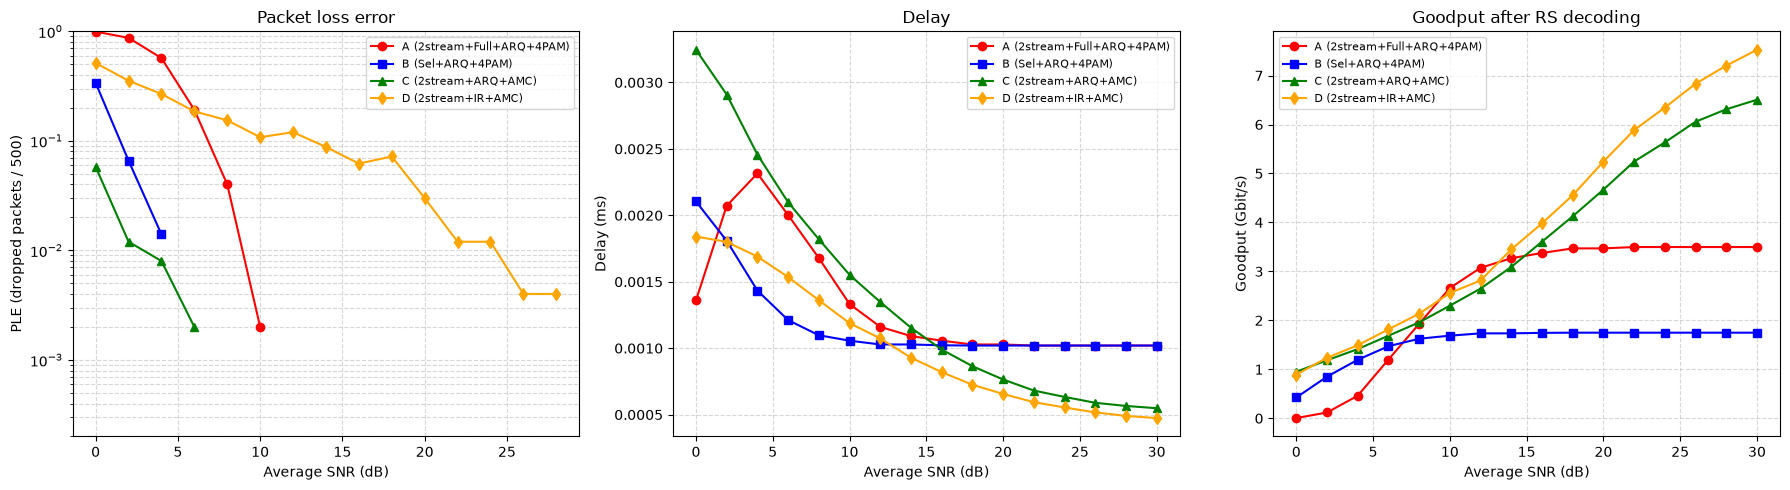

In [7]:
# So s?nh ARQ v? IR-HARQ b?ng RS(255,223)
from pathlib import Path
import sys
import time
import sys
import os


import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.channel import generate_composite_fading
from src.parameters import (
    PointingErrorConfig,
    ReceiverConfig,
    RISConfig,
    SystemConfig,
    TurbulenceConfig,
)
from src.per_model import amc_thresholds
from src import harq
import importlib
harq = importlib.reload(harq)

RS = {"n": 255, "k": 223, "s": 8}
R_SYM = 1e9
M_MAX = 3
PER_QOS = 1e-2
N_PACKETS = 500
M_LIST = [2, 4, 8, 16]
SNR_DB = np.arange(0, 31, 2)
SEED = 0


def goodput(result):
    """Delivered payload bits per second after successful RS decoding."""
    payload_bits = RS["k"] * RS["s"]
    return sum(
        delivered * payload_bits * R_SYM / symbols
        for delivered, symbols in zip(
            result["stream_delivered"], result["stream_symbols"]
        )
        if symbols > 0
    )


def average_delay_ms(result):
    """Average successful-packet delay in milliseconds."""
    if not result["delivered"]:
        return np.nan
    return (
        result["delay_symbols_sum"]
        / result["delivered"]
        / R_SYM
        * 1e3
    )


def build_config():
    config = SystemConfig(
        ris=RISConfig(K=2, N=[6, 6]),
        turbulence=TurbulenceConfig(alpha=3.35, beta=3.19),
        pointing_error=PointingErrorConfig(
            sigma_theta=2.0e-3,
            sigma_phi=2.0e-3,
        ),
        receiver=ReceiverConfig(gamma_th_db=13.0),
    )
    config.validate()
    return config


theta_db = amc_thresholds(
    M_LIST, RS["n"], RS["k"], RS["s"], PER_QOS
)
print("Analytical AMC thresholds (dB) at PER target:", theta_db)

config = build_config()
num_timeslots = N_PACKETS * (M_MAX + 1)
np.random.seed(SEED)
h = generate_composite_fading(config, num_timeslots)
K = config.ris.K
base_full = (h[:, 0] + h[:, 1]) ** 2 / K**2
base_selective = np.maximum(h[:, 0] ** 2, h[:, 1] ** 2)
base_branch_1 = 0.5 * h[:, 0] ** 2
base_branch_2 = 0.5 * h[:, 1] ** 2

names = [
    "A (Full+ARQ+4PAM)",
    "B (Sel+ARQ+4PAM)",
    "C (2stream+ARQ+AMC)",
    "D (2stream+IR+AMC)",
]
results = {
    name: {"ple": [], "delay": [], "goodput": []}
    for name in names
}
rng = np.random.default_rng(SEED)
start = time.perf_counter()

for snr_db in SNR_DB:
    average_snr = 10.0 ** (snr_db / 10.0)
    h_full = np.sqrt(average_snr * base_full)
    h_selective = np.sqrt(average_snr * base_selective)
    h_branch_1 = np.sqrt(average_snr * base_branch_1)
    h_branch_2 = np.sqrt(average_snr * base_branch_2)

    simulations = [
        harq.simulate_arq(
            h_full, RS, theta_db, M_fixed=4,
                M_max=M_MAX, N=N_PACKETS, rng=rng,
        ),
        harq.simulate_arq(
            h_selective, RS, theta_db, M_fixed=4,
            M_max=M_MAX, N=N_PACKETS, rng=rng,
        ),
        harq.simulate_two_stream(
            h_branch_1, h_branch_2, RS, theta_db,
            M_max=M_MAX, N=N_PACKETS, mode="arq", rng=rng,
        ),
        harq.simulate_two_stream(
            h_branch_1, h_branch_2, RS, theta_db,
            M_max=M_MAX, N=N_PACKETS, mode="ir", rng=rng,
        ),
    ]

    for name, result in zip(names, simulations):
        if result["delivered"] + result["dropped"] != N_PACKETS:
            raise RuntimeError(
                f"Invalid packet accounting for {name}: "
                f"delivered + dropped != {N_PACKETS}"
            )
        ple = (N_PACKETS - result["delivered"]) / N_PACKETS
        if not np.isclose(ple, result["dropped"] / N_PACKETS):
            raise RuntimeError(f"PLE mismatch for {name}")
        measured_goodput = goodput(result)
        results[name]["ple"].append(ple)
        results[name]["delay"].append(average_delay_ms(result))
        results[name]["goodput"].append(measured_goodput)

print(f"Simulation completed in {time.perf_counter() - start:.1f} s")
print("SNR points:", SNR_DB.tolist())
for name in names:
    print(name, "PLE:", results[name]["ple"])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = ["red", "blue", "green", "orange"]
markers = ["o", "s", "^", "d"]

for name, color, marker in zip(names, colors, markers):
    axes[0].plot(
        SNR_DB,
        np.where(
            np.asarray(results[name]["ple"]) > 0,
            np.asarray(results[name]["ple"]),
            np.nan,
        ),
        color=color, marker=marker, label=name,
    )
    axes[1].plot(
        SNR_DB, results[name]["delay"],
        color=color, marker=marker, label=name,
    )
    axes[2].plot(
        SNR_DB, np.asarray(results[name]["goodput"]) / 1e9,
        color=color, marker=marker, label=name,
    )

axes[0].set(
    xlabel="Average SNR (dB)",
    ylabel="PLE (dropped packets / 500)",
    title="Packet loss error",
)
axes[0].set_yscale("log")
axes[0].set_ylim(1 / (N_PACKETS * 10), 1.0)
axes[1].set(xlabel="Average SNR (dB)", ylabel="Delay (ms)", title="Delay")
axes[2].set(
    xlabel="Average SNR (dB)",
    ylabel="Goodput (Gbit/s)",
    title="Goodput after RS decoding",
)
for axis in axes:
    axis.grid(True, which="both", linestyle="--", alpha=0.5)
    axis.legend(fontsize=8)
fig.tight_layout()
plt.show()
